In [80]:
import warnings
warnings.filterwarnings('ignore')
#############################################
#BASIC PACKAGES
import sys,time,os
from copy import deepcopy as dcopy
import healpy as hp
import numpy as np
import matplotlib as mpl
import matplotlib.pyplot as plt
%matplotlib inline

#############################################
#PATH TO SCRIPTS FOLDER
path = '/data/AMARINS/LSSxHI-CODES/scripts/'
sys.path.insert(1, path)
import cross_functions_theory      as cxft
import cross_functions_simulations as cxfs
# it's required healpy  (https://healpy.readthedocs.io/en/latest/index.html)
import handling_data               as hdata
import pandas as pd
#############################################
## MATPLOTLIB FEATURES
from matplotlib import cm
font = {'weight' : 'bold','size'   : 22}
mpl.rc('font', **font)
mpl.rc('font',   size=209)  #set defaults so that the plots are readable
mpl.rc('axes',   titlesize=20)
mpl.rc('axes',   labelsize=20)
mpl.rc('xtick',  labelsize=20)
mpl.rc('ytick',  labelsize=20)
mpl.rc('legend', fontsize =20)
mpl.rc('figure', titlesize=20)
mpl.rc('text',   usetex=True)
## FURTHER MATPLOTLIB FEATURES
from matplotlib.lines import Line2D
from matplotlib.patches import Patch
from matplotlib.markers import MarkerStyle
from matplotlib.transforms import Affine2D
from matplotlib.colors import LinearSegmentedColormap, ListedColormap
#colors = ["#ffffcc", "#a1dab4", "#41b6c4", "#2c7fb8", "#253494"]
colors = ['#ff0000', "#41b6c4", '#0000ff']
my_cmap = ListedColormap(colors, name="my_cmap")
#my_cmap_r = my_cmap.reversed()
#############################################
## NAMASTER (https://namaster.readthedocs.io/en/latest/)
import pymaster as nmt
del_l  = 30
nside  = 256
##############################
b    = nmt.NmtBin.from_nside_linear(nside, nlb=del_l)
leff = b.get_effective_ells()
feff = leff*(leff+1)/2/np.pi

In [81]:
params_general = pd.Series({'verbose'  : 1,
                            'project'  : 'CX',
                            'threshold': 1e-25,
                            'optimized': False,
                           })

params_sims = pd.Series({'nreals'         : 100,
                         'nside'          : 256,                                          
                         'lmin'           : 0,                         
                         'lmax'           : int(3*256),
                         'apply_mask'     : 0,
                         'include_wn'     : 0,
                         'include_beam'   : 0,
                         'wn_sigma_pix'   : 0.154,
                         'beam_fwhm'      : 0.011635,        
                         'numin'          : 980,
                         'numax'          : 1260,
                         'nbands'         : 30,
                         'stokes'         : 'I',
                         'unit'           : 'mK',
                        })
               
params_tf = pd.Series({'tf_hixhi'        : 1,
                       'tf_gxhi'         : 1,
                       'auto_g_bin'      : 0,
                       'cross_g_bin'     : 0 ,
                       'auto_hi_bins'    : -1,
                       'cross_hi_bins'   : -1,
                       #'tf_variance'     : tf_variance, 
                       'estimator'       : 'huber',
                       'save_simulated'  : 1,
                       'save_theoretical': 1,
                       'save_hdf5'       : 1,
                       'save_txt'        : 0,
                      })   

params_chisel = pd.Series({'method'    :'ICA',
                           'wtransform':'identity',
                           'ns'        : 4})            

params_inout = pd.Series({'dirpath_chisel'      : '/data/AMARINS/chisel/scripts',
                          'dirpath_sims'        : '/data/AMARINS/LSSxHI-DATA/simulations/GCxHI/LSSTxLOWZ_40_0001/bin{b}',
                          'dirpath_foregrounds' : '/data/AMARINS/MAPS/FG256',
                          'dirpath_mask'        : '/data/AMARINS/MAPS/MASK',
                          #'dirpath_savedata'    : dirpath_savedata,                         
                          'filename_foregrounds': 'FG_I_256_980mhz1260mhz_30bins_full_nonfrps_L0.fits',                
                          #'filename_mask'       : filename_mask,
                          'filepath_field1'     : '/data/AMARINS/LSSxHI-DATA/theoretical/GCxHI/LSST_bin{b}_40_0001_HI_cl_LOWZ.txt',
                          'filepath_field2'     : '/data/AMARINS/LSSxHI-DATA/theoretical/GCxHI/LSST_bin{b}_40_0001_DENSITY_cl_LOWZ.txt',
                          'filepath_cross'      : '/data/AMARINS/LSSxHI-DATA/theoretical/GCxHI/LSST_bin{b}_40_0001_HIxDENSITY_cl_LOWZ.txt',
                          'pathout'             : '/data/AMARINS/LSSxHI-DATA/tfunction/LSST_40_0001__100sims_HIsky'
                       })

params_tf['auto_g_bin'] = 2
params_sims['l'] = np.arange(params_sims['lmin'], params_sims['lmax']+1, 1)	

try:
    if params_tf['auto_hi_bins']<0:
        params_tf['auto_hi_bins'] = np.arange(params_sims['nbands'], dtype=np.int32)
except:
    pass
################################
try:    
    if params_tf['cross_hi_bins']<0:
    #    params_inout['output']['cross_hi_bins'] = np.arange(params_fields['hi']['nbands'], dtype=np.int32)
        if params_tf['auto_g_bin']==0:
            params_tf['cross_hi_bins'] = np.array([0,1,2,3])
        elif params_tf['auto_g_bin']==1:
            params_tf['cross_hi_bins'] = np.array([4,5,6,7,8,9])
        elif params_tf['auto_g_bin']==2:
            params_tf['cross_hi_bins'] = np.array([10,11,12,13,14])
        elif params_tf['auto_g_bin']==3:
            params_tf['cross_hi_bins'] = np.array([15,16,17,18])
        elif params_tf['auto_g_bin']==4:
            params_tf['cross_hi_bins'] = np.array([18,19,20,21])
        elif params_tf['auto_g_bin']==5:
            params_tf['cross_hi_bins'] = np.array([22,23,24])
        elif params_tf['cross_g_bin']==6:
            params_tf['cross_hi_bins'] = np.array([25,26,27])        
        elif params_tf['auto_g_bin']==7:
            params_tf['cross_hi_bins'] = np.array([28,29])       
        else:
            params_tf['cross_hi_bins'] = np.array([28,29])             
except:
    pass
params_tf['cross_g_bin'] = dcopy( np.asarray( params_tf['cross_g_bin'] ) )
params_tf['auto_g_bin' ] = dcopy( np.asarray( params_tf['auto_g_bin' ] ) )

try:
    params_general['project' ] = params_general['project' ].format(b=params_tf['auto_g_bin'])    
except:
    pass
try:
    params_inout['dirpath_savedata' ] = params_inout['dirpath_savedata' ].format(b=params_tf['auto_g_bin'])    
except:
    pass         
try:
    params_inout['dirpath_sims' ] = params_inout['dirpath_sims' ].format(b=params_tf['auto_g_bin'])    
except:
    pass     
try:    
    params_inout['filepath_field1'] = params_inout['filepath_field1'].format(b=params_tf['auto_g_bin'])    
except:
    pass
try:
    params_inout['filepath_field2'] = params_inout['filepath_field2'].format(b=params_tf['auto_g_bin'])    
except:
    pass   
try:    
    params_inout['filepath_cross' ] = params_inout['filepath_cross' ].format(b=params_tf['auto_g_bin'])    
except:
    pass    

In [82]:
sys.path.insert(1, params_inout['dirpath_chisel'])    
import Extension4BINGO   as cs
import load_standard_params as loadparams
#import pyMRS as pymrs
import statcosmo as statc
params_maps    = loadparams.load_params_maps()
params_CS      = loadparams.load_params_CS()
params_WT      = loadparams.load_params_WT()
#params_path_cs = loadparams.load_params_path('amarins')
####
#modifying chisel params
del params_maps['iseed']    
params_CS['method']     = dcopy(params_chisel['method'])
params_CS['wtransform'] = dcopy(params_chisel['wtransform'])
params_CS['ns']         = dcopy(params_chisel['ns'])
##############################################################################################################################
#loading Foregrodun (FG) maps and the mask
HDU         = 1 #0: Olivari data. 1: Marins data
Mfg = hdata.getmap(dirpath_=params_inout.dirpath_foregrounds, filename_=params_inout.filename_foregrounds, healpix_readingformat=False, hdu=HDU)
if (params_sims.apply_mask) and (params_inout.dirpath_mask!="") and (params_inout.filename_mask!=""):
    MASK = hdata.getmap(dirpath_=params_inout.dirpath_mask, filename_=params_inout.filename_mask, healpix_readingformat=False, hdu=1)
    params_chisel['coverage_flag'] = 'masked'
    if params_inout['pathout'] =="":
        params_inout['pathout'] = 'masked'    
else:
    MASK = np.ones_like(Mfg[0,:])
    params_chisel['coverage_flag'] = 'fullsky'
    if params_inout['pathout'] =="":
        params_inout['pathout'] = 'fullsky'

#hdata.file_verification( params_inout['dirpath_savedata'], '', '')#, params_inout['pathout'] )
#params_inout['dirpath_savedata'] = os.path.join(params_inout['dirpath_savedata'], params_inout['pathout'] )
#hdata.file_verification(params_inout['dirpath_savedata'],'','ns{}'.format(params_CS['ns']))
#params_inout['dirpath_savedata_ns'] = os.path.join(params_inout['dirpath_savedata'],'ns{}'.format(params_CS['ns']))   
##############################################################################################################################
output_info = {'field':'field', 'nside':params_sims.nside, 
               'frequency'   :{'min':params_sims.numin, 'max':params_sims.numax,'nbands':params_sims.nbands,  'unit':params_sims.unit}, 
               'stokes'      :params_sims['stokes'],
               'coverage'    :None,#params_chisel['coverage_flag'], 
               #'pathout'     :params_inout['dirpath_savedata_ns'],
               'apply_beam'  :False, 
               'namePL'      :False, 
               'nameFG'      :params_inout.filename_foregrounds, 
               #'apply_mask'  :params_sims.apply_mask, 
               #'nameM'       :params_inout.filename_mask,               
               'pathdir_N'   :False
              }

output_info['filename'] = hdata.new_formattingnames(F=output_info['field'], 
                                                    S=output_info['stokes'], 
                                                    NSIDE_=output_info['nside'], 
                                                    freq_min=int(output_info['frequency']['min']), 
                                                    freq_max=int(output_info['frequency']['max']),
                                                    freq_unit=output_info['frequency']['unit'],
                                                    Num_=output_info['frequency']['nbands'], 
                                                    C=output_info['coverage'], 
                                                    Bres=None,Bmodel=None,A=None, R='')
##############################################################################################################################
clf1 = np.loadtxt(params_inout['filepath_field1']).T
clf2 = np.loadtxt(params_inout['filepath_field2']).T
clcx = np.loadtxt(params_inout['filepath_cross'] ).T 
print('Done!')

Done!


In [83]:
###############################################
## SIMULATIONS
params_sims['nreals'] = 5

itime         = time.time() #['alm_hi_sim', 'cl_hi_sim', 'cl_kappa_sim', 'cl_cross_sim', 'alm_kappa_sim']
varnames      = ['alm_hi_sim','alm_kappa_sim' , 'cl_hi_sim', 'cl_kappa_sim', 'cl_cross_sim']#,'cross_correlation_coef']
dict_all      = cxfs.get_file_simulated_data(path_=params_inout['dirpath_sims'], varnames=varnames, nsims_to_use=params_sims.nreals)
dict_all_mean = cxfs.dict_averages_from_loaded_data(dict_all_=dict_all, varnames_=varnames)
nsims         = int(dict_all_mean[varnames[0]]['bin1']['matrix'].shape[0]    )
if params_general['verbose']: print('Loading time for {0:d} sims: {1:.2f} seg'.format(nsims, time.time()-itime)) 
del nsims

params_sims['realizations'] = np.asarray(list(dict_all.keys()))
if params_general['verbose']: print("Using sims: ",params_sims['realizations'])
#######################################################################################################
N=params_sims['nbands']

#filename = ""
#Xfg_smoothed = Mfg
#alpha_ch_list = []
#alpha_cx_list = []

Loading time for 5 sims: 20.27 seg
Using sims:  ['sim0' 'sim1' 'sim10' 'sim100' 'sim1000']


In [84]:
# MOCK ##########################################
jsim0      = params_sims['realizations'][0]
alm_hi_obs = dict_all[jsim0]['alm_hi_sim'][2:]
#################################################
nside = params_sims.nside
npix  = hp.nside2npix(nside)
#################################################
Xhi   = np.zeros((alm_hi_obs.shape[0], npix))
for num in range(alm_hi_obs.shape[0]):
        Xhi[num] = hp.alm2map(np.ascontiguousarray(alm_hi_obs[num]), params_sims.nside, pol=False, verbose=False)    
#################################################
Xfg0 = hdata.getmap(dirpath_=params_inout.dirpath_foregrounds, 
                   filename_=params_inout.filename_foregrounds, 
                   healpix_readingformat=False, 
                   hdu=1)    

In [85]:
params_sims['realizations']

array(['sim0', 'sim1', 'sim10', 'sim100', 'sim1000'], dtype='<U7')

In [91]:
params_sims['realizations'][1:][0]

'sim1'

In [94]:
############################################################
### SKY = FG + HI
############################################################
alpha_cx_list = []
Ae_1_list =  []
Ae_2_list =  []
for j, jsim in enumerate(params_sims['realizations'][1:]):
    print('Job {} -- Sim: {}'.format(j+1, jsim))
    #################################################
    params_maps["getdata"] = "observed"   
    params_cs, params_wt = cs.load(params_CS, params_WT)
    #################################################
    ### Loading Mhi e Mg mocks (independent realizations)
    alm_g_sim   = dict_all[jsim]['alm_kappa_sim'][2:,:]        
    alm_hi_jsim = dict_all[jsim]['alm_hi_sim'][2:]    
    Mg   = hp.alm2map(alms=np.ascontiguousarray(alm_g_sim[0]),nside=nside,pol=False)
    Mhi  = np.vstack([ hp.alm2map(np.ascontiguousarray(alm_hi_jsim[num]), 
                                  nside, pol=False, verbose=False) \
                       for num in range(alm_hi_jsim.shape[0]) ])     
    #################################################
    ### Filtering 1: Injecting HI mock (Mhi)
    Xfg  = dcopy(Xfg0)
    Xsky = Xfg  + Xhi;
    X    = Xsky + Mhi
    #
    X    = cs.adaptation_maps(X, params_maps, params_inout)
    Xr   = cs.maps2CSmaps(X, params_wt, params_cs, verbose=False)# , False)
    Ae_1 = Xr['mixmatrix']
    #Ae_inv  = np.dot(np.linalg.inv(np.dot(Ae.T, Ae)), Ae.T)
    #Wfg_1   = np.dot(Ae, Ae_inv)    
    C1   = Xr['reconstruction']['21cm']#FG removal residual
    params_cs, params_wt = cs.load(params_CS, params_WT)    
    #################################################
    ### Filtering 2: No injected HI mock (Mhi)
    Xfg  = dcopy(Xfg0)
    Xsky = Xfg  + Xhi;
    X    = Xsky + 0*Mhi
    #
    X   = cs.adaptation_maps(X, params_maps, params_inout)
    Xr  = cs.maps2CSmaps(X, params_wt, params_cs, verbose=False)# , False)
    Ae_2= Xr['mixmatrix']
    C0  = Xr['reconstruction']['21cm']#FG removal residual
    #################################################
    ### 1) Create the maps of difference of residuals (w/ and w/o HI): Xc
    ### 2) take each alm of each Xc map: alm_c
    ### 3) cross correlate alm_c and alm_g (mock): cross_(c,g)
    ### 4) cross correlate alm_hi (mock) and alm_g (mock): cross_(hi,g)
    ### 5) calculate the transfer function:  tf = cross_(hi,g)/cross_(c,g)
    Xc = C1-C0
    alm_c_sim    = np.vstack([ hp.map2alm(maps=m, pol=False) for m in Xc   ])
    alm_mock_sim = np.vstack([ hp.map2alm(maps=m, pol=False) for m in Mhi ])
    #alm_hi_est = np.vstack([ hp.map2alm(maps=m, pol=False) for m in Xr['reconstruction']['21cm'] ])    
    #
    cx_c    = np.vstack([ hp.alm2cl(alms1=alm_g_sim, alms2=i_alm) for i_alm in alm_c_sim    ])
    cx_mock = np.vstack([ hp.alm2cl(alms1=alm_g_sim, alms2=i_alm) for i_alm in alm_mock_sim ])
        
    alpha_cx = cx_mock/cx_c
    alpha_cx_list.append(alpha_cx.flatten())
    Ae_1_list.append(Ae_1.flatten())
    Ae_2_list.append(Ae_2.flatten())
    ndim_cx = alpha_cx.shape

Job 1 -- Sim: sim1


In [95]:
############################################################
### SKY = FG + 0
############################################################
alphap_cx_list = []
Aep_1_list =  []
Aep_2_list =  []
for j, jsim in enumerate(params_sims['realizations'][1:]):
    print('Job {} -- Sim: {}'.format(j+1, jsim))
    #################################################
    params_maps["getdata"] = "observed"   
    params_cs, params_wt = cs.load(params_CS, params_WT)
    #################################################
    ### Loading Mhi e Mg mocks (independent realizations)
    alm_g_sim   = dict_all[jsim]['alm_kappa_sim'][2:,:]        
    alm_hi_jsim = dict_all[jsim]['alm_hi_sim'][2:]    
    Mg   = hp.alm2map(alms=np.ascontiguousarray(alm_g_sim[0]),nside=nside,pol=False)
    Mhi  = np.vstack([ hp.alm2map(np.ascontiguousarray(alm_hi_jsim[num]), 
                                  nside, pol=False, verbose=False) \
                       for num in range(alm_hi_jsim.shape[0]) ])     
    #################################################
    ### Filtering 1: Injecting HI mock (Mhi)
    Xfg  = dcopy(Xfg0)
    Xsky = Xfg  + 0*Xhi;
    X    = Xsky + Mhi
    #
    X    = cs.adaptation_maps(X, params_maps, params_inout)
    Xr   = cs.maps2CSmaps(X, params_wt, params_cs, verbose=False)# , False)
    Aep_1= Xr['mixmatrix']
    #Ae_inv  = np.dot(np.linalg.inv(np.dot(Ae.T, Ae)), Ae.T)
    #Wfg_1   = np.dot(Ae, Ae_inv)    
    C1   = Xr['reconstruction']['21cm']#FG removal residual
    params_cs, params_wt = cs.load(params_CS, params_WT)    
    #################################################
    ### Filtering 2: No injected HI mock (Mhi)
    Xfg  = dcopy(Xfg0)
    Xsky = Xfg  + 0*Xhi;
    X    = Xsky + 0*Mhi
    #
    X    = cs.adaptation_maps(X, params_maps, params_inout)
    Xr   = cs.maps2CSmaps(X, params_wt, params_cs, verbose=False)# , False)
    Aep_2= Xr['mixmatrix']
    C0   = Xr['reconstruction']['21cm']#FG removal residual
    #################################################
    ### 1) Create the maps of difference of residuals (w/ and w/o HI): Xc
    ### 2) take each alm of each Xc map: alm_c
    ### 3) cross correlate alm_c and alm_g (mock): cross_(c,g)
    ### 4) cross correlate alm_hi (mock) and alm_g (mock): cross_(hi,g)
    ### 5) calculate the transfer function:  tf = cross_(hi,g)/cross_(c,g)
    Xc = C1-C0
    alm_c_sim    = np.vstack([ hp.map2alm(maps=m, pol=False) for m in Xc   ])
    alm_mock_sim = np.vstack([ hp.map2alm(maps=m, pol=False) for m in Mhi ])
    #alm_hi_est = np.vstack([ hp.map2alm(maps=m, pol=False) for m in Xr['reconstruction']['21cm'] ])    
    #
    cx_c    = np.vstack([ hp.alm2cl(alms1=alm_g_sim, alms2=i_alm) for i_alm in alm_c_sim    ])
    cx_mock = np.vstack([ hp.alm2cl(alms1=alm_g_sim, alms2=i_alm) for i_alm in alm_mock_sim ])
    ndim_cx = alpha_cx.shape
    
    alphap_cx = cx_mock/cx_c
    alphap_cx_list.append(alphap_cx.flatten())
    Aep_1_list.append(Aep_1.flatten())
    Aep_2_list.append(Aep_2.flatten())

Job 1 -- Sim: sim1


In [96]:
N=4
##################################
### SKY = FG+HI
alpha_cx_flat = np.vstack(alpha_cx_list)
alpha_cx_sim, alpha_cx_sim_err = statc.get_estimator(alpha_cx_flat, 'huber', axis=0)#, **kwargs)
#alpha_cx_sim_err = np.sqrt(alpha_cx_sim_err).reshape(N,-1)
alpha_cx_sim = alpha_cx_sim.reshape(N,-1)

##################################
### SKY = FG+0
alphap_cx_flat = np.vstack(alphap_cx_list)
alphap_cx_sim, _ = statc.get_estimator(alphap_cx_flat, 'huber', axis=0)#, **kwargs)
alphap_cx_sim = alphap_cx_sim.reshape(N,-1)



Ae_1_list  = np.array(Ae_1_list)
Ae_2_list  = np.array(Ae_2_list)
Aep_1_list = np.array(Aep_1_list)
Aep_2_list = np.array(Aep_2_list)

In [99]:
################################### 
#                                 #
# OBSERVATIONAL CROSS CORRELATION #
#                                 # 
###################################
print("Realization of observation: ",jsim0)
##################################
## loading HI and Galaxy realization alms
alm_hi_jsim = dict_all[jsim0]['alm_hi_sim'][2:]
alm_g_sim   = dict_all[jsim0]['alm_kappa_sim'][2:,:]
##################################
## from alm to maps
npix = hp.nside2npix(params_sims.nside)
Xg   = hp.alm2map(alms=np.ascontiguousarray(alm_g_sim[0]),nside=256,pol=False)
Xhi  = np.vstack([ hp.alm2map(alms=np.ascontiguousarray(i_alm),nside=256,pol=False) for i_alm in alm_hi_jsim])
Xfg  = hdata.getmap(dirpath_=params_inout.dirpath_foregrounds, filename_=params_inout.filename_foregrounds, healpix_readingformat=False, hdu=1)
##################################
## Filtering: SKY = HI + FG
params_maps["getdata"] = "observed"
Xsky = Xfg + Xhi;
X    = Xsky
## Foreground removal
params_cs, params_wt = cs.load(params_CS, params_WT)
X   = cs.adaptation_maps(X, params_maps, params_inout)
Xr  = cs.maps2CSmaps(X, params_wt, params_cs)# , False)
#Ae  = Xr['mixmatrix']
R   = Xr['reconstruction']['21cm'] # R = <HI> + residuals
##################################
## Cross correlation observation: <R,Galaxy>
CX = np.vstack([ hp.anafast(map1=iR,map2=Xg,pol=False) for iR in R])
#Ae_inv  = np.dot(np.linalg.inv(np.dot(Ae.T, Ae)), Ae.T)
#Wfg   = np.dot(Ae, Ae_inv)    

Realization of observation:  sim0


In [33]:
Ae_1_list.shape

(4, 120)

In [100]:
def get_w(_A=None):
    _W   = np.dot(np.linalg.inv(np.dot(_A.T, _A)), _A.T)
    _Wfg = np.dot(_A, _W)
    return _W, _Wfg

In [101]:
index_sim = 0
#
nch, ncomp = Ae_1.shape
Ae2  = Ae_2_list[index_sim].reshape(nch,ncomp)
Aep2 = Aep_2_list[index_sim].reshape(nch,ncomp)

W2,Wfg2   = get_w(Ae2)
Wp2,Wfgp2 = get_w(Aep2)

In [102]:
Xfg  = dcopy(Xfg0)
Xsky = Xfg + Xhi
######
Xfg2  = np.dot(Wfg2 , Xsky) #fg filtered
Xfgp2 = np.dot(Wfgp2, Xsky) #fg filtered

In [103]:
cmap_ae  = plt.get_cmap("Blues_r", 5+2)
cmap_aep = plt.get_cmap("Reds_r" , 5+2)

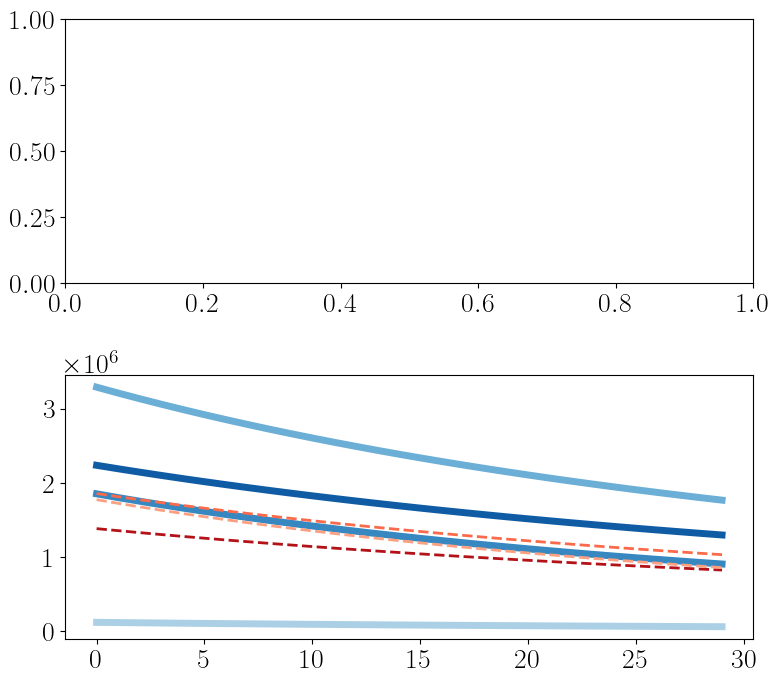

In [113]:
fig   = plt.figure()
grid  = plt.GridSpec(2,1,top=1.4,right=1.2, wspace=0.03, hspace=0.35)
############################################################
ax  = plt.subplot(grid[0]) 
#
index_sim = 0
#
nch, ncomp = Ae_1.shape
Ae1  = Ae_1_list[index_sim].reshape(nch,ncomp).T
Ae2  = Ae_2_list[index_sim].reshape(nch,ncomp).T
Aep1 = Aep_1_list[index_sim].reshape(nch,ncomp).T
Aep2 = Aep_2_list[index_sim].reshape(nch,ncomp).T
#
#for i in range(ncomp):
    #ax.plot(Ae1[i] , color=cmap_ae( i+2), lw=5)
    #ax.plot(Aep1[i], color=cmap_aep(i+1), lw=2, ls='dashed')

ax  = plt.subplot(grid[1]) 
for i in range(ncomp):
    if 1:
        ax.plot(np.abs( Ae2[i] ) , color=cmap_ae( i+1), lw=5)
        ax.plot(np.abs( Aep2[i] ), color=cmap_aep(i+1), lw=2, ls='dashed')
#ax.scatter(leff, clrec, color='blue', s=10)
#ax.scatter(leff, cldeb_hi, color='forestgreen', s=100, marker='+')
#for l in leff: ax.axvline(x=l, c='black', ls='dashed', lw=0.3)
#ax.set_xlim(30,400)  
#ax.set_ylim(1e-7,3e-5)  
#ax.set_yscale('log'); ax.set_xscale('linear')
############################################
plt.show()

In [ ]:
def get_w(_A=None):
    _W   = np.dot(np.linalg.inv(np.dot(_A.T, _A)), _A.T)
    _Wfg = np.dot(_A, _W)
    return _W, _Wfg

In [156]:
############################################################
### SKY = FG + HI
############################################################
j==0
jsim = 'sim10'
#################################################
params_maps["getdata"] = "observed"   
params_cs, params_wt = cs.load(params_CS, params_WT)
#################################################
### Loading Mhi e Mg mocks (independent realizations)
alm_g_sim   = dict_all[jsim]['alm_kappa_sim'][2:,:]        
alm_hi_jsim = dict_all[jsim]['alm_hi_sim'][2:]    
Mg   = hp.alm2map(alms=np.ascontiguousarray(alm_g_sim[0]),nside=nside,pol=False)
Mhi  = np.vstack([ hp.alm2map(np.ascontiguousarray(alm_hi_jsim[num]), 
                              nside, pol=False, verbose=False) \
                   for num in range(alm_hi_jsim.shape[0]) ]) 
Xfg  = hdata.getmap(dirpath_=params_inout.dirpath_foregrounds, 
                    filename_=params_inout.filename_foregrounds, 
                    healpix_readingformat=False, hdu=1)
#################################################
### Filtering 2: No injected HI mock (Mhi)
Xsky = Xfg  + Xhi;
#
X   = cs.adaptation_maps(Xsky, params_maps, params_inout)
Xr  = cs.maps2CSmaps(X, params_wt, params_cs, verbose=False)# , False)
Ae  = Xr['mixmatrix']

In [160]:
Ae.shape, Aep.shape

((30, 4), (30, 4))

In [157]:
############################################################
### SKY = FG + HI
############################################################
j==0
jsim = 'sim10'
#################################################
params_maps["getdata"] = "observed"   
params_cs, params_wt = cs.load(params_CS, params_WT)
#################################################
### Loading Mhi e Mg mocks (independent realizations)
alm_g_sim   = dict_all[jsim]['alm_kappa_sim'][2:,:]        
alm_hi_jsim = dict_all[jsim]['alm_hi_sim'][2:]    
Mg   = hp.alm2map(alms=np.ascontiguousarray(alm_g_sim[0]),nside=nside,pol=False)
Mhi  = np.vstack([ hp.alm2map(np.ascontiguousarray(alm_hi_jsim[num]), 
                              nside, pol=False, verbose=False) \
                   for num in range(alm_hi_jsim.shape[0]) ]) 
Xfg  = hdata.getmap(dirpath_=params_inout.dirpath_foregrounds, 
                    filename_=params_inout.filename_foregrounds, 
                    healpix_readingformat=False, hdu=1)
#################################################
### Filtering 2: No injected HI mock (Mhi)
Xsky = Xfg  + 0*Xhi;
#
X   = cs.adaptation_maps(Xsky, params_maps, params_inout)
Xr  = cs.maps2CSmaps(X, params_wt, params_cs, verbose=False)# , False)
Aep = Xr['mixmatrix']

In [158]:
W,Wfg   = get_w(Ae)
Wp,Wfgp = get_w(Aep)

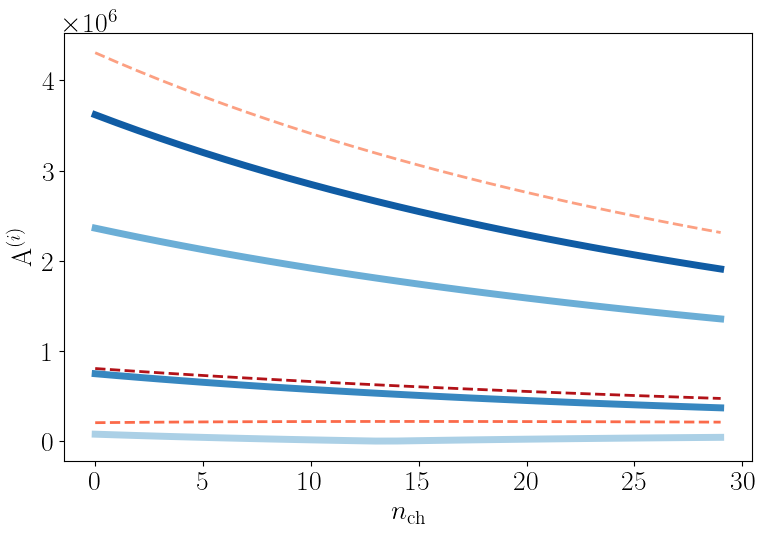

In [159]:
fig   = plt.figure()
grid  = plt.GridSpec(1,1,top=1.0,right=1.2, wspace=0.03, hspace=0.35)
############################################################
ax  = plt.subplot(grid[0]) 
for i in range(Ae.shape[1]):
    ax.plot(np.abs( Ae.T[i] ) , color=cmap_ae( i+1), lw=5) #with HI
    ax.plot(np.abs( Aep.T[i] ), color=cmap_aep(i+1), lw=2, ls='dashed') #without HI
ax.set_ylabel(r'$\textrm{A}^{(i)}$')
ax.set_xlabel(r'$n_{\rm ch}$')
############################################
plt.show()

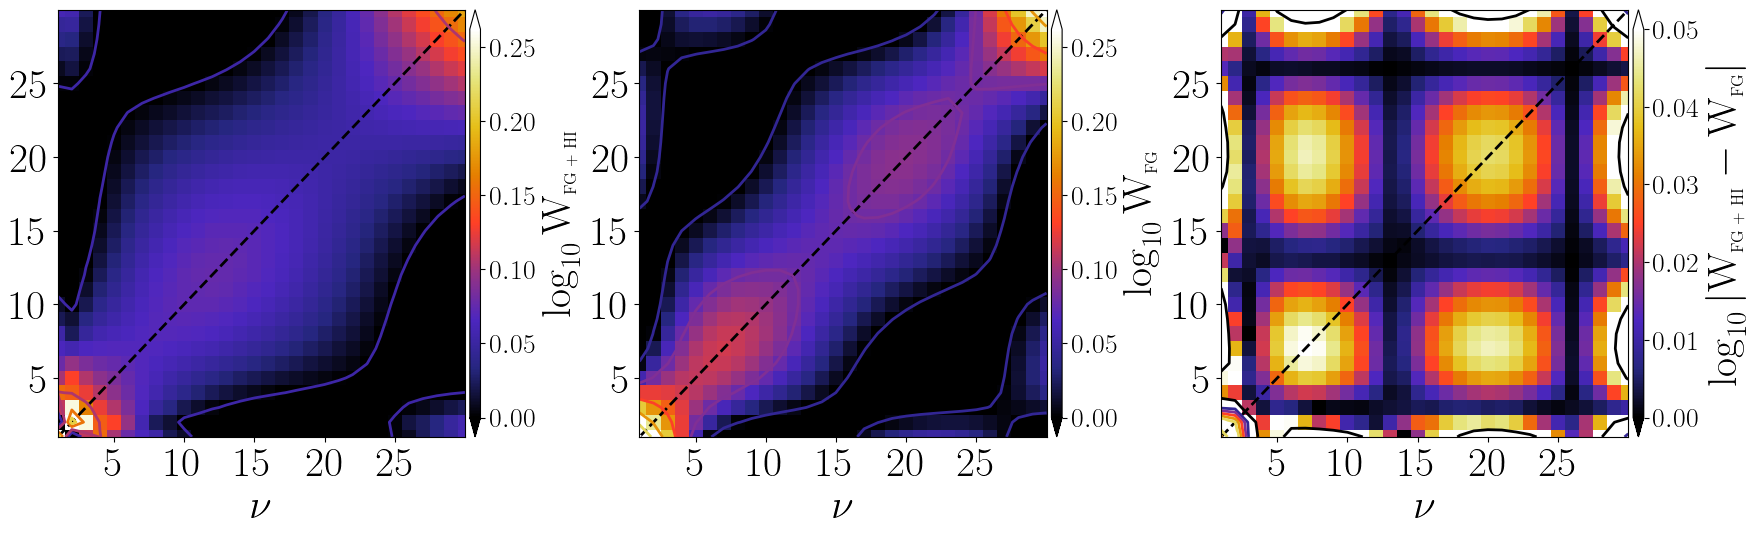

In [161]:
savefigs = True
nmin,nmax = 0,29
############################################################################
ncols,nrows = 3,1
fig, axes   = plt.subplots(nrows=nrows, ncols=ncols)
fig.subplots_adjust(top=nrows*1.,right=ncols*0.9, wspace=0.2,hspace=0.55)
############################################################################
cticks   = [5,10,15,20,25]
CMAP = 'CMRmap'
bwidth=3
WFGs = [Wfg,Wfgp, np.abs(Wfg-Wfgp) ]
#######
for ii, iWfg in enumerate(WFGs):#for ii, ins in enumerate(WFG_dict.keys()):
    ax  = axes[ii] 
    iWfg = iWfg[nmin:nmax+1,nmin:nmax+1]
    x   = np.arange(iWfg.shape[0])+1
    y   = np.arange(iWfg.shape[1])+1
    x,y = np.meshgrid(x, y)
    z   = np.log(1+iWfg)
    #######
    if ii<2:im = ax.pcolormesh(x, y, z, cmap=CMAP, vmin=np.log(1+0), vmax=np.log(1+0.3))
    else: im = ax.pcolormesh(x, y, z, cmap=CMAP, vmin=0, vmax=0.05)
    ax.plot(np.arange(iWfg.shape[0])+1,np.arange(iWfg.shape[0])+1, color='black',lw=2,ls='--')
    CS = ax.contour(   x, y, z, cmap=CMAP, extend='both',  linewidths=2,)
    cbar = plt.colorbar(im, ax=ax,extend='both',shrink=1.,pad=0.01,aspect=40, location="right")
    if ii==0:   cbar.set_label(label=r'$\log_{10}\textrm{W}_{\textrm{\large FG + HI}}$', fontsize=30)
    elif ii==1: cbar.set_label(label=r'$\log_{10}\textrm{W}_{\textrm{\large FG}}$', fontsize=30)    
    else:    cbar.set_label(label=r'$\log_{10}|\textrm{W}_{\textrm{\large FG + HI}}-\textrm{W}_{\textrm{\large FG}}|$', fontsize=30)
    cbar.ax.tick_params(labelsize=20) 
    ax.set_xticks(cticks)
    ax.set_yticks(cticks)
    ax.set_xlabel(r'$\nu$', fontsize=30)
    ax.tick_params(axis='both', labelsize=30)
    ax.set_xlabel(r'$\nu$', fontsize=30)
    ax.axis([x.min(), x.max(), y.min(), y.max()])
plt.show()

In [164]:
W,Wfg   = get_w(Ae)
Wp,Wfgp = get_w(Aep)

In [175]:
Clkg  = np.vstack([ hp.anafast(map1= Xfg[i]-np.dot(Wfg,Xfg)[i], pol=False) for i in range(30) ])
Clkgp = np.vstack([ hp.anafast(map1= Xfg[i]-np.dot(Wfgp,Xfg)[i], pol=False) for i in range(30) ])
Clfg  = np.vstack([ hp.anafast(map1= Xfg[i], pol=False) for i in range(30) ])

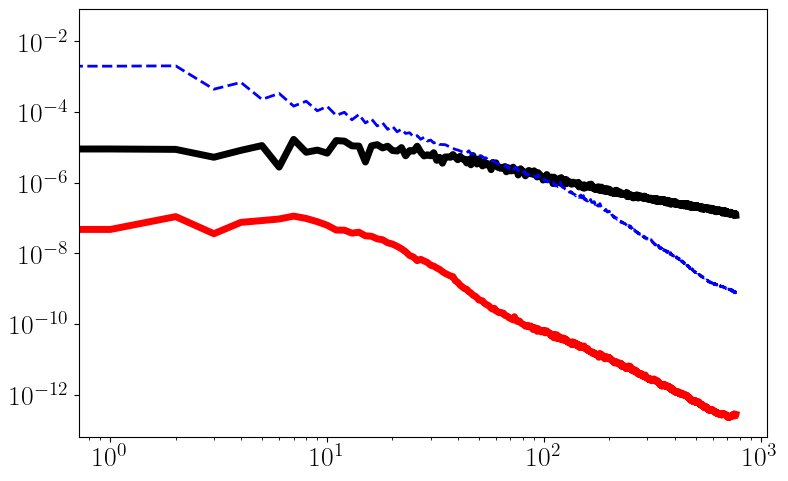

In [176]:
fig   = plt.figure()
grid  = plt.GridSpec(1,1,top=1.0,right=1.2, wspace=0.03, hspace=0.35)
############################################################
i=10
ax  = plt.subplot(grid[0]) 
ax.loglog(np.arange(768), Clshi[i] , color='black', lw=5) #with HI
ax.loglog(np.arange(768), Clkg[i] , color='red', lw=5) #with HI
ax.loglog(np.arange(768), Clkgp[i], color='blue', lw=2, ls='dashed') #without HI
#ax.set_ylabel(r'$\textrm{A}^{(i)}$')
#ax.set_xlabel(r'$n_{\rm ch}$')
############################################
plt.show()

In [184]:
Xsky = Xfg  + Xhi
Cls  = np.vstack([ hp.anafast(map1= Xsky[i]-np.dot(Wfg,Xsky)[i], pol=False) for i in range(30) ])
Clsp = np.vstack([ hp.anafast(map1= Xsky[i]-np.dot(Wfgp,Xsky)[i], pol=False) for i in range(30) ])

In [185]:
Clshi  = np.vstack([ hp.anafast(map1= Xhi[i], pol=False) for i in range(30) ])

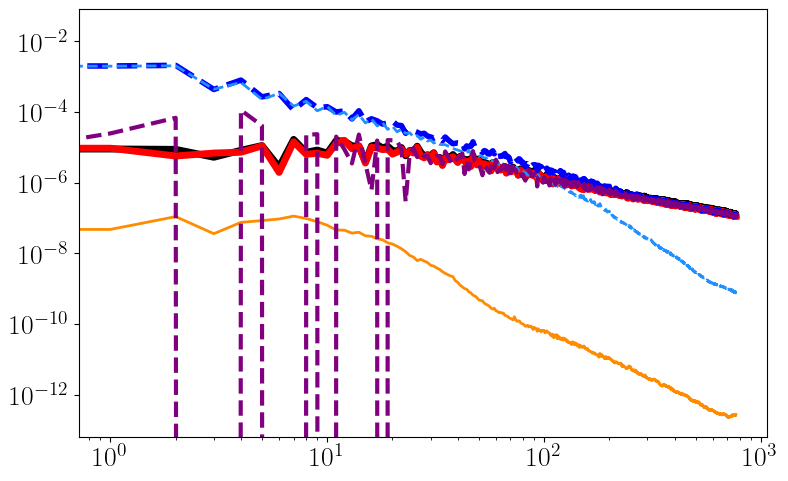

In [186]:
fig   = plt.figure()
grid  = plt.GridSpec(1,1,top=1.0,right=1.2, wspace=0.03, hspace=0.35)
############################################################
i=10
ax  = plt.subplot(grid[0]) 
ax.loglog(np.arange(768), Clshi[i] , color='black', lw=5) #with HI
ax.loglog(np.arange(768), Cls[i] , color='red', lw=5) #with HI
ax.loglog(np.arange(768), Clsp[i], color='blue', lw=4, ls='dashed') #without HI

ax.loglog(np.arange(768), Clkg[i] , color='darkorange', lw=2) #with HI
ax.loglog(np.arange(768), Clkgp[i], color='dodgerblue', lw=2, ls='dashed') #without HI

ax.loglog(np.arange(768), Clsp[i]-Clkgp[i], color='purple', lw=3, ls='dashed') #without HI
#ax.set_ylabel(r'$\textrm{A}^{(i)}$')
#ax.set_xlabel(r'$n_{\rm ch}$')
############################################
plt.show()

In [173]:
Xsky = Xfg  + Xhi
Xsky = Xsky-np.dot(Wfg,Xsky)
Cls  = np.vstack([ hp.anafast(map1= Xsky[i], pol=False) for i in range(30) ])
Xsky = Xfg  + 0*Xhi
Xsky = Xsky-np.dot(Wfgp,Xsky)
Clsp = np.vstack([ hp.anafast(map1= Xsky[i], pol=False) for i in range(30) ])

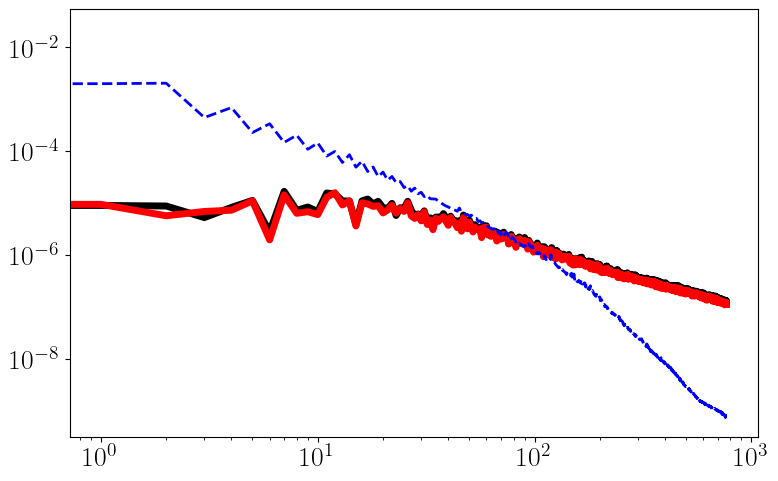

In [174]:
fig   = plt.figure()
grid  = plt.GridSpec(1,1,top=1.0,right=1.2, wspace=0.03, hspace=0.35)
############################################################
i=10
ax  = plt.subplot(grid[0]) 
ax.loglog(np.arange(768), Clshi[i] , color='black', lw=5) #with HI
ax.loglog(np.arange(768), Cls[i] , color='red', lw=5) #with HI
ax.loglog(np.arange(768), Clsp[i], color='blue', lw=2, ls='dashed') #without HI
#ax.set_ylabel(r'$\textrm{A}^{(i)}$')
#ax.set_xlabel(r'$n_{\rm ch}$')
############################################
plt.show()

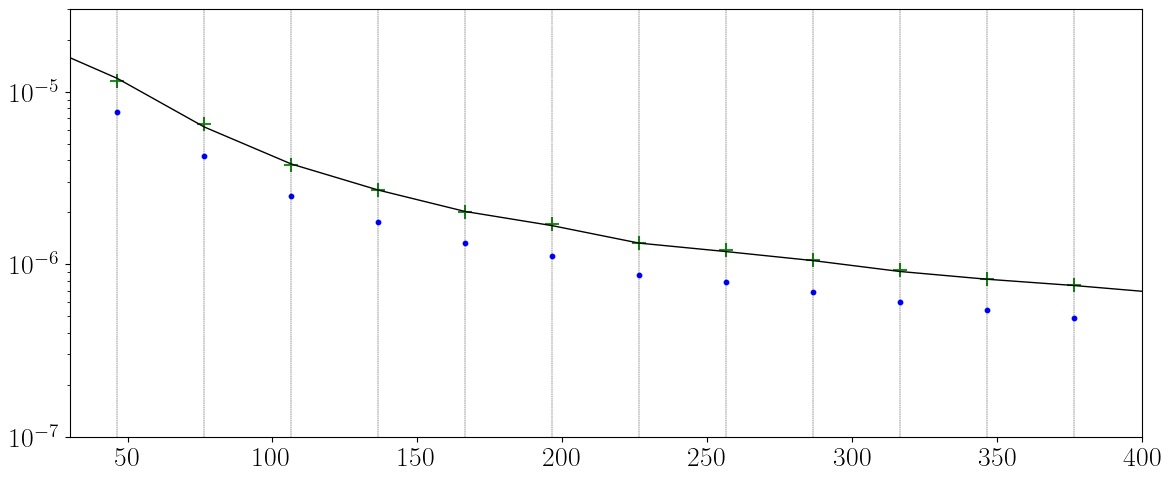

In [30]:
fig   = plt.figure()
grid  = plt.GridSpec(1,1,top=1.0,right=1.8, wspace=0.03, hspace=0.35)
############################################################
ax  = plt.subplot(grid[0]) 
#
index_bin = 3
ibin = params_tf['cross_hi_bins'][index_bin]
#
l = np.arange(3*256)#leff[filter_ell]
fact = 1#l*(l+1)/2/np.pi
clrec = b.bin_cell( fact*CX[ibin,:] )
cldeb_hi = b.bin_cell( fact*CX[ibin,:]*alpha_cx_sim[ibin,:] )
clthr = dict_all[jsim0]['cl_cross_sim'][1:]
clthr = b.bin_cell(  fact*clthr[ibin,:] )
#
ax.plot(leff, clthr, color='black', lw=1)
ax.scatter(leff, clrec, color='blue', s=10)
ax.scatter(leff, cldeb_hi, color='forestgreen', s=100, marker='+')
for l in leff: ax.axvline(x=l, c='black', ls='dashed', lw=0.3)
ax.set_xlim(30,400)  
ax.set_ylim(1e-7,3e-5)  
ax.set_yscale('log'); ax.set_xscale('linear')
############################################
plt.show()

## ------------------------------------------------------------------------------------------------------------

## ------------------------------------------------------------------------------------------------------------

In [31]:
def tf_processing(dict_all_=None, reali_mocks=None, reali_obs=None, 
                  params_sims_=None, params_maps_=None, params_inout_=None,
                  tf_estimator=None,
                  params_WT_=None,  params_CS_=None, obs_include_hi=True,
                  verbose=True, verbose_level=0,
                  type_='switzer'):
    f= 1 if obs_include_hi else 0
    job_verbose = verbose==True and verbose_level>0
    cs_verbose  = verbose==True and verbose_level>1
    #reali_mocks=params_sims_['realizations'][1:]
    #reali_obs  =params_sims_['realizations'][0]    
    #FG obs-----        
    Xfg0 = hdata.getmap(dirpath_=params_inout_.dirpath_foregrounds, 
                       filename_=params_inout_.filename_foregrounds, 
                       healpix_readingformat=False, 
                       hdu=1)
    #HI obs-----    
    jsim0      = reali_obs#params_sims_['realizations'][0]
    alm_hi_obs = dict_all_[jsim0]['alm_hi_sim'][2:]
    npix       = hp.nside2npix(params_sims_.nside)
    Xhi0  = np.vstack([ hp.alm2map(np.ascontiguousarray(alm_hi_obs[num]), params_sims_.nside, pol=False, verbose=False) \
                        for num in range(alm_hi_obs.shape[0]) ])        
    #TF-----          
    npix = hp.nside2npix(params_sims_.nside)
    if type_.lower()=='switzer':
        alpha_cx_list = []
        for j, jsim in enumerate(reali_mocks):
            if job_verbose: print('Job {} -- Sim: {}'.format(j+1, jsim))
            params_maps_["getdata"] = "observed"                
            alm_hi_jsim = dict_all_[jsim]['alm_hi_sim'][2:]#mock
            # --- Loading Xhi realization
            Mhi  = np.vstack([ hp.alm2map(np.ascontiguousarray(alm_hi_jsim[num]), params_sims_.nside, pol=False, verbose=False) \
                            for num in range(alm_hi_jsim.shape[0]) ])                
            # --- Filtering 1
            Xfg  = dcopy(Xfg0)
            Xhi  = dcopy(Xhi0)
            WN   = np.zeros_like(Mhi)   
            Xsky = Xfg + f*Xhi;
            params_cs, params_wt = cs.load(params_CS_, params_WT_)
            X  = Xsky + Mhi
            #
            X  = cs.adaptation_maps(X, params_maps_, params_inout_)
            Xr = cs.maps2CSmaps(X, params_wt, params_cs, verbose=cs_verbose)# , False)
            C1 = Xr['reconstruction']['21cm']
            # --- Filtering 2
            Xfg  = dcopy(Xfg0)
            Xhi  = dcopy(Xhi0)
            WN   = np.zeros_like(Mhi)   
            Xsky = Xfg + f*Xhi;
            params_cs, params_wt = cs.load(params_CS_, params_WT_)
            X  = Xsky + 0*Mhi
            #
            X   = cs.adaptation_maps(X, params_maps_, params_inout_)
            Xr  = cs.maps2CSmaps(X, params_wt, params_cs, verbose=cs_verbose)# , False)
            C0  = Xr['reconstruction']['21cm']
            # -------------------------------------
            Xc = C1-C0
            alm_c_sim    = np.vstack([ hp.map2alm(maps=m, pol=False) for m in Xc   ])
            alm_mock_sim = np.vstack([ hp.map2alm(maps=m, pol=False) for m in Mhi ])
            alm_g_sim    = dict_all_[jsim]['alm_kappa_sim'][2:,:]#mock
            #alm_hi_est = np.vstack([ hp.map2alm(maps=m, pol=False) for m in Xr['reconstruction']['21cm'] ])    
            #
            cx_c    = np.vstack([ hp.alm2cl(alms1=alm_g_sim, alms2=i_alm) for i_alm in alm_c_sim    ])
            cx_mock = np.vstack([ hp.alm2cl(alms1=alm_g_sim, alms2=i_alm) for i_alm in alm_mock_sim ])
                
            alpha_cx = cx_mock/cx_c
            alpha_cx_list.append(alpha_cx.flatten())
                
            ndim_cx = alpha_cx.shape
            alpha_cx_flat = np.vstack(alpha_cx_list)
            alpha_cx_sim, alpha_cx_sim_err = statc.get_estimator(alpha_cx_flat, tf_estimator, axis=0)#, **kwargs)
            alpha_cx_sim_err = np.sqrt(alpha_cx_sim_err).reshape(N,-1)
            alpha_cx_sim = alpha_cx_sim.reshape(N,-1)
        return {'tf':alpha_cx_sim, 'errtf':alpha_cx_sim_err, 'realization_mocks': reali_mocks, 'realization_obs':reali_obs,
                'HIobs':Xhi0,'FGobs':Xfg0}           
        
    elif type_.lower()=='fba':
        alpha_cx_list = []
        for j, jsim in enumerate(reali_mocks):
            if job_verbose: print('Job {} -- Sim: {}'.format(j+1, jsim))
            params_maps_["getdata"] = "observed"                
            alm_hi_jsim = dict_all_[jsim]['alm_hi_sim'][2:]#mock
            # --- Loading Xhi realization
            npix = hp.nside2npix(params_sims_.nside)
            Mhi  = np.zeros((alm_hi_jsim.shape[0], npix))
            for num in range(alm_hi_jsim.shape[0]):
                    Mhi[num] = hp.alm2map(np.ascontiguousarray(alm_hi_jsim[num]), params_sims_.nside, pol=False, verbose=False)    
            #
            Xfg  = dcopy(Xfg0)
            Xsky = Xfg + f*Mhi;
            X    = Xsky #+ Mhi
            # --- Filtering
            params_cs, params_wt = cs.load(params_CS_, params_WT_)            
            X  = cs.adaptation_maps(X, params_maps_, params_inout_)
            Xr = cs.maps2CSmaps(X, params_wt, params_cs, verbose=cs_verbose)# , False)
            R  = Xr['reconstruction']['21cm']
            # -------------------------------------
            alm_g_sim = dict_all_[jsim]['alm_kappa_sim'][2:,:]#mock
            Xg        = hp.alm2map(alms=np.ascontiguousarray(alm_g_sim[0]),nside=256,pol=False)
            #
            cx_res = np.vstack([ hp.anafast(map1=iR, map2=Xg, pol=False) for iR in R   ])
            cx_inp = np.vstack([ hp.anafast(map1=iH, map2=Xg, pol=False) for iH in Mhi ])            
                
            alpha_cx = cx_inp/cx_res
            alpha_cx_list.append(alpha_cx.flatten())
                
            ndim_cx = alpha_cx.shape
            alpha_cx_flat = np.vstack(alpha_cx_list)
            alpha_cx_sim, alpha_cx_sim_err = statc.get_estimator(alpha_cx_flat, tf_estimator, axis=0)#, **kwargs)
            alpha_cx_sim_err = np.sqrt(alpha_cx_sim_err).reshape(N,-1)
            alpha_cx_sim = alpha_cx_sim.reshape(N,-1)
        return {'tf':alpha_cx_sim, 'errtf':alpha_cx_sim_err, 'realization_mocks': reali_mocks, 'realization_obs':reali_obs,
                'HIobs':Xhi0,'FGobs':Xfg0}      
    else:
        raise NameError('Type not accept: ', type_.lower())
        

In [43]:
TF_hi = tf_processing(dict_all_=dict_all, 
                      reali_mocks=params_sims['realizations'][1:], 
                      reali_obs=params_sims['realizations'][0], 
                      params_sims_=params_sims, params_maps_=params_maps, params_inout_=params_inout,
                      tf_estimator=params_tf['estimator'],
                      params_WT_=params_WT,  params_CS_=params_CS, obs_include_hi=True,
                      verbose=True, verbose_level=1, type_='switzer')
print('done!')

Job 1 -- Sim: sim1
Job 2 -- Sim: sim10
Job 3 -- Sim: sim100
Job 4 -- Sim: sim1000
Job 5 -- Sim: sim1001
Job 6 -- Sim: sim1002
Job 7 -- Sim: sim1003
Job 8 -- Sim: sim1004
Job 9 -- Sim: sim1005
Job 10 -- Sim: sim1006
Job 11 -- Sim: sim1007
Job 12 -- Sim: sim1008
Job 13 -- Sim: sim1009
Job 14 -- Sim: sim101
Job 15 -- Sim: sim1010
Job 16 -- Sim: sim1011
Job 17 -- Sim: sim1012
Job 18 -- Sim: sim1013
Job 19 -- Sim: sim1014
Job 20 -- Sim: sim1015
Job 21 -- Sim: sim1016
Job 22 -- Sim: sim1017
Job 23 -- Sim: sim1018
Job 24 -- Sim: sim1019
Job 25 -- Sim: sim102
Job 26 -- Sim: sim1020
Job 27 -- Sim: sim1021
Job 28 -- Sim: sim1022
Job 29 -- Sim: sim1023
Job 30 -- Sim: sim1024
Job 31 -- Sim: sim1025
Job 32 -- Sim: sim1026
Job 33 -- Sim: sim1027
Job 34 -- Sim: sim1028
Job 35 -- Sim: sim1029
Job 36 -- Sim: sim103
Job 37 -- Sim: sim1030
Job 38 -- Sim: sim1031
Job 39 -- Sim: sim1032
Job 40 -- Sim: sim1033
Job 41 -- Sim: sim1034
Job 42 -- Sim: sim1035
Job 43 -- Sim: sim1036
Job 44 -- Sim: sim1037
Job 45

In [ ]:
TF_no = tf_processing(dict_all_=dict_all, 
                      reali_mocks=params_sims['realizations'][1:], 
                      reali_obs=params_sims['realizations'][0], 
                      params_sims_=params_sims, params_maps_=params_maps, params_inout_=params_inout,
                      tf_estimator=params_tf['estimator'],
                      params_WT_=params_WT,  params_CS_=params_CS, obs_include_hi=False,
                      verbose=True, verbose_level=1, type_='switzer')
print('done!')

Job 1 -- Sim: sim1
Job 2 -- Sim: sim10


In [45]:
jsim0      = params_sims['realizations'][0]
#alm_hi_jsim = dict_all[jsim0]['alm_hi_sim'][2:]
alm_g_sim = dict_all[jsim0]['alm_kappa_sim'][2:,:]
# --- Loading Xhi realization
npix = hp.nside2npix(params_sims.nside)
Xhi  = TF_hi['HIobs']  
params_maps["getdata"] = "observed"
# --- Filtering 1
Xfg  = dcopy(Xfg_smoothed)
Xsky = Xfg + Xhi;
X    = Xsky
#
params_cs, params_wt = cs.load(params_CS, params_WT)
X   = cs.adaptation_maps(X, params_maps, params_inout)
Xr  = cs.maps2CSmaps(X, params_wt, params_cs)# , False)
Ae  = Xr['mixmatrix']
Xg  = hp.alm2map(alms=np.ascontiguousarray(alm_g_sim[0]),nside=256,pol=False)
R   = Xr['reconstruction']['21cm']
#Ae_inv  = np.dot(np.linalg.inv(np.dot(Ae.T, Ae)), Ae.T)
#Wfg   = np.dot(Ae, Ae_inv)    
#C0      = np.dot(Wfg, Xsky+0*Mhi)  
#cx_mock = np.vstack([ hp.alm2cl(alms1=alm_g_sim, alms2=i_alm) for i_alm in alm_mock_sim ])

In [46]:
CX = np.vstack([ hp.anafast(map1=iR,map2=Xg,pol=False) for iR in R])

In [47]:
jsim0 = TF_hi['realization_obs']
alpha_no = TF_no['tf'][params_tf['cross_hi_bins'],:]
alpha_hi = TF_hi['tf'][params_tf['cross_hi_bins'],:]

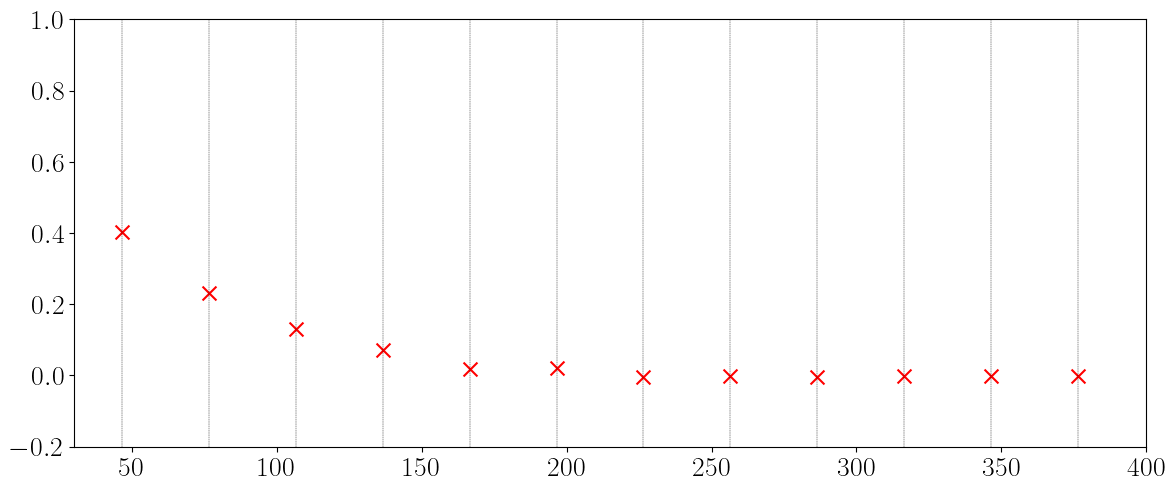

In [53]:
fig   = plt.figure()
grid  = plt.GridSpec(1,1,top=1.0,right=1.8, wspace=0.03, hspace=0.35)
############################################################
ax  = plt.subplot(grid[0]) 
#
index_bin = 2
ibin = params_tf['cross_hi_bins'][index_bin]
#
l = np.arange(3*256)#leff[filter_ell]
fact = 1#l*(l+1)/2/np.pi
clrec = b.bin_cell( fact*CX[ibin,:] )
tf_no = b.bin_cell( TF_no['tf'][ibin,:] )
tf_hi = b.bin_cell( TF_hi['tf'][ibin,:] )
#
ax.scatter(leff, 1-tf_no/tf_hi, color='red', s=100, marker='x')
#ax.scatter(leff, tf_hi, color='forestgreen', s=100, marker='+')
for l in leff: ax.axvline(x=l, c='black', ls='dashed', lw=0.3)
ax.set_xlim(30,400)  
ax.set_ylim(-0.2,1)  
ax.set_yscale('linear'); ax.set_xscale('linear')
############################################
plt.show()

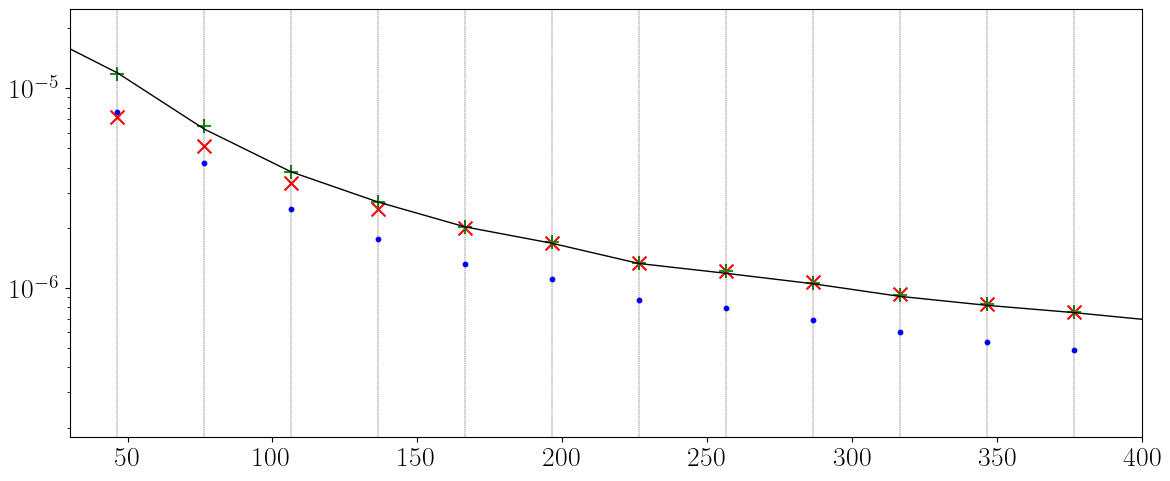

In [54]:
fig   = plt.figure()
grid  = plt.GridSpec(1,1,top=1.0,right=1.8, wspace=0.03, hspace=0.35)
############################################################
ax  = plt.subplot(grid[0]) 
#
index_bin = 3
ibin = params_tf['cross_hi_bins'][index_bin]
#
l = np.arange(3*256)#leff[filter_ell]
fact = 1#l*(l+1)/2/np.pi
clrec = b.bin_cell( fact*CX[ibin,:] )
cldeb_no = b.bin_cell( fact*CX[ibin,:]*TF_no['tf'][ibin,:] )
cldeb_hi = b.bin_cell( fact*CX[ibin,:]*TF_hi['tf'][ibin,:] )
clthr = dict_all[jsim0]['cl_cross_sim'][1:]
clthr = b.bin_cell(  fact*clthr[ibin,:] )
#
ax.plot(leff, clthr, color='black', lw=1)
ax.scatter(leff, clrec, color='blue', s=10)
ax.scatter(leff, cldeb_no, color='red', s=100, marker='x')
ax.scatter(leff, cldeb_hi, color='forestgreen', s=100, marker='+')
for l in leff: ax.axvline(x=l, c='black', ls='dashed', lw=0.3)
ax.set_xlim(30,400)  
#ax.set_ylim(1e-7,3e-5)  
ax.set_yscale('log'); ax.set_xscale('linear')
############################################
plt.show()

In [198]:
np.array(['sim{}'.format(i) for i in range(1,10,1)])

array(['sim1', 'sim2', 'sim3', 'sim4', 'sim5', 'sim6', 'sim7', 'sim8',
       'sim9'], dtype='<U4')

In [217]:
dict_all_=dict_all
reali_mocks=params_sims['realizations'][1:10+1]
reali_obs  =params_sims['realizations'][0]
params_sims_=params_sims 
params_maps_=params_maps 
params_inout_=params_inout
tf_estimator ='huber'
params_WT_=params_WT
params_CS_=params_CS

In [218]:
f = 1
Xfg0 = hdata.getmap(dirpath_=params_inout_.dirpath_foregrounds, 
                   filename_=params_inout_.filename_foregrounds, 
                   healpix_readingformat=False, 
                   hdu=1)
#HI obs-----    
jsim0      = reali_obs#params_sims_['realizations'][0]
alm_hi_obs = dict_all_[jsim0]['alm_hi_sim'][2:]
nside = params_sims_.nside
npix  = hp.nside2npix(nside)
Xhi0  = np.vstack([ hp.alm2map(np.ascontiguousarray(alm_hi_obs[num]), nside, pol=False, verbose=False) \
                    for num in range(alm_hi_obs.shape[0]) ])
alpha_cx_list = []
for j, jsim in enumerate(reali_mocks):
    print('Job {} -- Sim: {}'.format(j+1, jsim))
    params_maps_["getdata"] = "observed"                
    alm_hi_jsim = dict_all_[jsim]['alm_hi_sim'][2:]#mock
    # --- Loading Xhi realization
    Mhi  = np.vstack([ hp.alm2map(np.ascontiguousarray(alm_hi_jsim[num]), nside, pol=False, verbose=False) \
                    for num in range(alm_hi_jsim.shape[0]) ])
    #
    Xfg  = dcopy(Xfg0)
    #Xhi  = dcopy(Xhi0)
    Xsky = Xfg + f*Mhi
    X    = Xsky
    # --- Filtering
    params_cs, params_wt = cs.load(params_CS_, params_WT_)            
    X  = cs.adaptation_maps(X, params_maps_, params_inout_)
    Xr = cs.maps2CSmaps(X, params_wt, params_cs, verbose=0)# , False)
    R  = Xr['reconstruction']['21cm']
    # -------------------------------------
    alm_g_sim = dict_all_[jsim]['alm_kappa_sim'][2:,:]#mock
    Xg        = hp.alm2map(alms=np.ascontiguousarray(alm_g_sim[0]),nside=256,pol=False)
    #
    cx_res = np.vstack([ hp.anafast(map1=iR, map2=Xg, pol=False) for iR in R   ])
    cx_inp = np.vstack([ hp.anafast(map1=iH, map2=Xg, pol=False) for iH in Mhi ])            
        
    alpha_cx = cx_inp/cx_res
    alpha_cx_list.append(alpha_cx.flatten())
        
    ndim_cx = alpha_cx.shape
    alpha_cx_flat = np.vstack(alpha_cx_list)
    alpha_cx_sim, alpha_cx_sim_err = statc.get_estimator(alpha_cx_flat, tf_estimator, axis=0)#, **kwargs)
    alpha_cx_sim_err = np.sqrt(alpha_cx_sim_err).reshape(N,-1)
    alpha_cx_sim = alpha_cx_sim.reshape(N,-1)
TF_dict = {'tf':alpha_cx_sim, 'errtf':alpha_cx_sim_err, 'realization_mocks': reali_mocks, 'realization_obs':reali_obs,
            'HIobs':Xhi0,'FGobs':Xfg0}   

Job 1 -- Sim: sim1
Job 2 -- Sim: sim10
Job 3 -- Sim: sim100
Job 4 -- Sim: sim1000
Job 5 -- Sim: sim1001
Job 6 -- Sim: sim1002
Job 7 -- Sim: sim1003
Job 8 -- Sim: sim1004
Job 9 -- Sim: sim1005
Job 10 -- Sim: sim1006


In [219]:
jsim0      = reali_obs#params_sims_['realizations'][0]
# HI ----
alm_hi_obs = dict_all_[jsim0]['alm_hi_sim'][2:]
Xhi        = np.vstack([ hp.alm2map(np.ascontiguousarray(alm_hi_obs[num]), 
                                                         nside, pol=False, 
                                                         verbose=False) \
                    for num in range(alm_hi_obs.shape[0]) ])
# FG ----
Xfg = hdata.getmap(dirpath_=params_inout_.dirpath_foregrounds, 
                   filename_=params_inout_.filename_foregrounds, 
                   healpix_readingformat=False, 
                   hdu=1)
# Ga ----
alm_g_sim = dict_all_[jsim0]['alm_kappa_sim'][2:,:]
Xg  = hp.alm2map(alms=np.ascontiguousarray(alm_g_sim[0]),nside=256,pol=False)
#----------------------------
# --- Loading Xhi realization
params_maps["getdata"] = "observed"
params_cs, params_wt = cs.load(params_CS, params_WT)
#
X = Xfg + Xhi
X   = cs.adaptation_maps(X, params_maps, params_inout)
Xr  = cs.maps2CSmaps(X, params_wt, params_cs)# , False)
Ae  = Xr['mixmatrix']
R   = Xr['reconstruction']['21cm']

In [221]:
CXthr = dict_all[jsim0]['cl_cross_sim'][1:]
CXsim = np.vstack([ hp.anafast(map1=iH, map2=Xg, pol=False) for iH in Xhi])
CXrec = np.vstack([ hp.anafast(map1=iR, map2=Xg, pol=False) for iR in R  ])

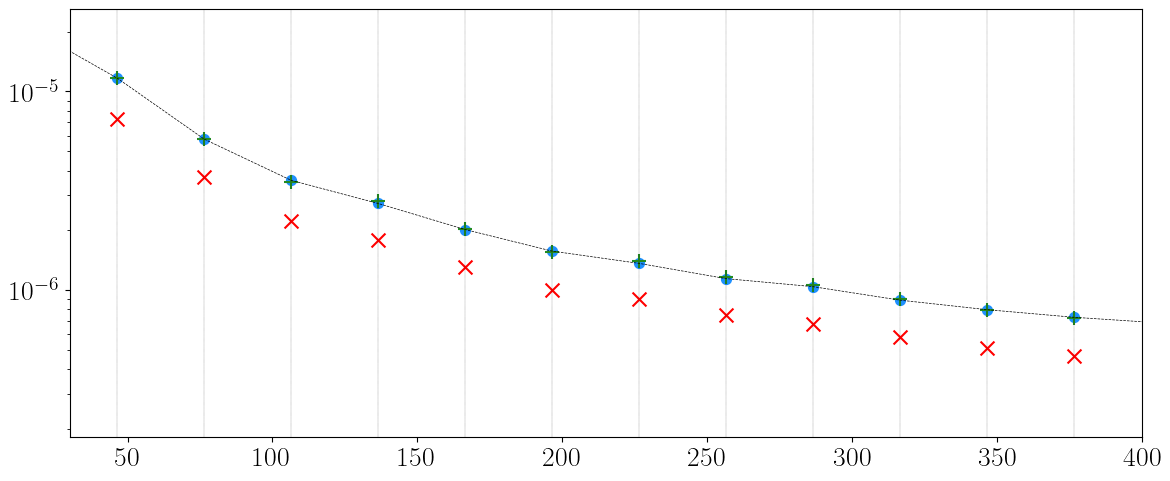

In [231]:
fig   = plt.figure()
grid  = plt.GridSpec(1,1,top=1.0,right=1.8, wspace=0.03, hspace=0.35)
############################################################
ax  = plt.subplot(grid[0]) 
#
index_bin = 2
ibin = params_tf['cross_hi_bins'][index_bin]
#
l = np.arange(3*256)#leff[filter_ell]
fact  = 1 #l*(l+1)/2/np.pi
clthr = b.bin_cell( fact*CXthr[ibin,:] )
clsim = b.bin_cell( fact*CXsim[ibin,:] )
clrec = b.bin_cell( fact*CXrec[ibin,:] )
cldeb = b.bin_cell( fact*CXrec[ibin,:]*TF_dict['tf'][ibin,:] )
#
ax.plot(   leff, clthr, color='black', lw=0.5, ls='dashed')
ax.scatter(leff, clsim, color='dodgerblue', s=50)
ax.scatter(leff, clrec, color='red', s=100, marker='x')
ax.scatter(leff, cldeb, color='forestgreen', s=100, marker='+')
for l in leff: ax.axvline(x=l, c='black', ls='dashed', lw=0.15)
ax.set_xlim(30,400)  
#ax.set_ylim(1e-7,3e-5)  
ax.set_yscale('log'); ax.set_xscale('linear')
############################################
plt.show()

In [57]:
import joblib
data_dict = joblib.load("tf_data.joblib")

In [60]:
data_dict.keys()

dict_keys([1, 2, 3, 4, 5, 6, 7])

In [61]:
#import pickle
#with open("my_data.pkl", "rb") as f:
    #data_dict = pickle.load(f)
#data_dict[1]["tf_hi"]["tf"]
#data_dict[1]["Xr"]["reconstruction"]["21cm"]
#data_dict[3]["tf_no"]["errtf"]

In [63]:
data_dict[1].keys()

dict_keys(['tf_hi', 'tf_no', 'jsim0', 'CX', 'R', 'Xg', 'Xr'])